# Quantum Metal iSWAP example 1 — two concentric transmons coupled directly, lumped readout resonators (Quantcore PDK rebuild)

**What the chip is.** Example 1 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. Applied 10,
034050 (2018), "only roughly": the notebook says the point is the structure of each device, not its exact geometry;
© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/iswap1_concentric_direct.md`): two `TransmonConcentricType2` qubits (disk + ring with a SQUID, mm
scale: ring radius 2 mm) at −45° / 135°, joined by a straight 4.6 mm line between their `pin2` fingers. Each qubit's
`pin3` finger is wired to a corner of a `ResonatorLumped` (a 14-turn meander in a 5 × 5 mm metal frame), whose side
pin goes to a launchpad. A third launchpad carries a drive line that ends open (`OpenToGround`) 500 µm below qubit
1's ring. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the netlist and the LOM are ours.

| | Qiskit Metal example 1 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 32 × 20 mm centred at (1, 3) mm | 32 × 25 mm (the 10 mm pockets overhang the source's chip; Designer = Metal + (15, 7.5) mm), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | three `LaunchpadWirebond`s 0.8–1.3 mm inside the chip | the same pads, moved to **100 µm** (`frame.pad_edge`) from the edge they face (south, south, east); the geometry that ends on them follows their ties |
| junctions | SQUIDs (Metal junction lines, 10 nH assumed) | Quantcore trilayer SQUIDs **sized for 4.0 GHz** (the bottom of the PDK band; R_n far below the window, flagged) |
| pockets | never drawn (metal-only cells) | `metal:Rectangle` pockets (lead decision, option b) |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| lines | `RouteStraight` (100 µm trace) | 100 µm metal strips + wires inside the pockets, `metal:PolylineCPW` outside, on Metal's route points |

**Kept exactly:** every component with the tutorial's options, positions and orientations; every line between the
tutorial's pins along Metal's own route points (`RouteStraight`, 100 µm trace as the tutorial's `cpw_width = 0.1mm`,
Metal's 6 µm gap; route4/5 with their 1 mm start leads).

**Substituted (lead decision, option b): the pockets Metal never draws.** All three key cells are metal-only in
Metal: `TransmonConcentricType2` leaves its pocket line commented out, and `ResonatorLumped` draws its frame and trace
as metal. Built exactly, they are ground plane (as in Metal's own GDS) and there is no circuit. Each gets a pocket, a
`metal:Rectangle` with `subtract: true`:
- **qubits:** the pocket Metal computes, `pocket_w × pocket_h` = 10 × 10 mm (its defaults), centred on the qubit and
  rotated with it;
- **resonators:** the box inside the 10 µm frame (4980 × 4980 µm) plus a 200 × 720 µm slot through the frame's 200 µm
  top break around the `final` segment: the meander is then shorted to the frame (ground plane) and ends open at
  `pin_n`, the λ/4 that the LOM model describes.

**Consequences, also substitutions:**
1. The two 10 mm pockets cover route1, route2, route3, route6 and the pad of `P1_C`. Metal draws metal over every
   pocket; a qcc route (or a Metal cell's metal inside another cell's pocket) does not. So those four lines are drawn
   as their 100 µm traces (`metal:Rectangle`, metal) joined to the pins by wires (`d.couple(..., wire=True)`), and
   `P1_C`'s pad as a 500 × 1000 µm metal rectangle (route6 runs over its 122 µm taper). route4 / route5, outside the
   pockets, are `metal:PolylineCPW` (100 / 6 µm) on Metal's own corner points.
2. The tutorial wires the resonators by their frame pins (`pin_sw`, `pin_se`, `pin_east`, `pin_west`) as if the
   frame carried the signal. With the pocket inside the frame, the frame is ground plane, so route2–route5 end on
   ground: the qubits' `pin3` fingers are grounded, and `P2_C` / `P3_C` see a short. The resonators couple to nothing
   (an exact replica cannot do better: the source has no conductor between a frame pin and the meander).
3. **Chip 32 × 25 mm** (source 32 × 20 mm, centred at (1, 3) mm): resonator1 already overhangs the source's chip by
   536 µm, and the 10 mm pockets by 4.07 mm at the top and bottom.

**Assumed coupling (kept):** the drive line's open end faces qubit 1's ring across 500 µm; no route carries this, so
it is declared (`Cd_qubit1`, coplanar-strip estimate, rough).

The notebook goes step by step: PDK → die → pads → components → lines → centring → DRC → netlist → LOM → FEM job →
results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.lom import estimates as est
LINE = dict(trace_width="0.1mm")                 # the tutorial's cpw_width; Metal's cpw_gap 6 µm

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 32 × 25 mm box gets the QCT frame; the three launchpads go 100 µm from the edges they face; both qubits get a trilayer SQUID sized on the PDK junction rule; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
mm-scale design needs a 32 × 25 mm box. Metal's chip spans x −15…17 mm, and y −7.5…17.5 mm here, so a Metal
position (x, y) is `P(x, y)` = (15000 + x, 7500 + y); `turn` rotates a local offset with a rotated cell.

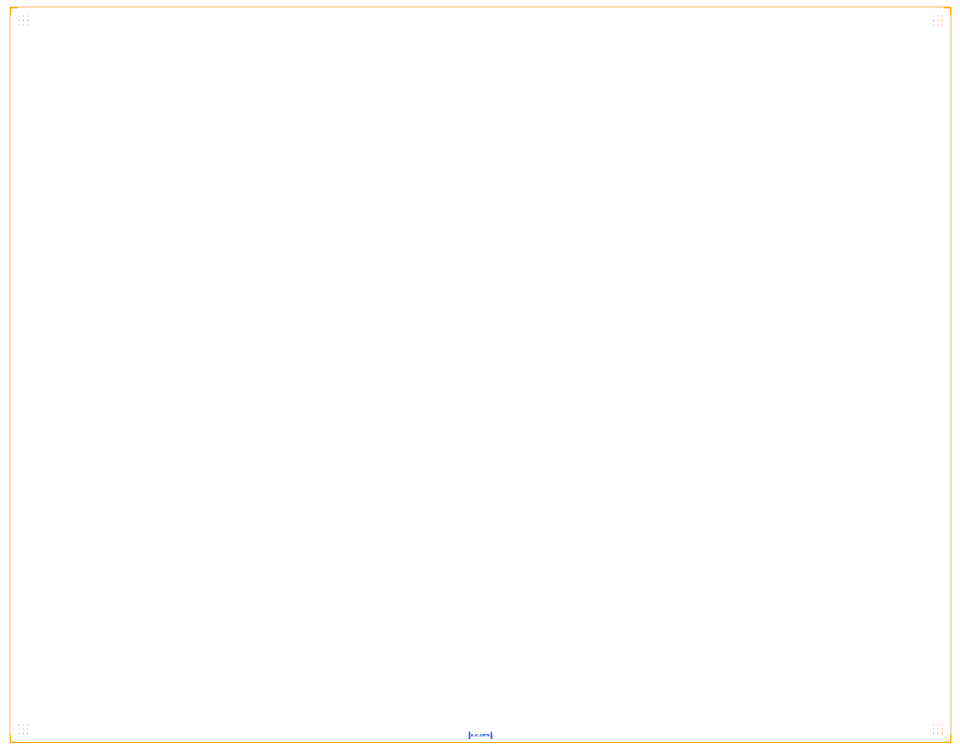

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_die.png')

In [4]:
d = Designer("iswap1_concentric_direct", box=(0, 0, 32000, 25000), chip={"name_chip": "MetalISWAP1"}, live=LIVE)
X0, Y0 = 15000, 7500                             # Metal's chip spans x −15…17 mm; y −7.5…17.5 mm here (see above)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm


def turn(x, y, deg):                             # rotate a local offset by deg
    c, s = math.cos(math.radians(deg)), math.sin(math.radians(deg))
    return x * c - y * s, x * s + y * c


rebuild(d)
snap(d, OUT / "iswap1_concentric_direct_step_die.png", size=(960, 750), width=400)

## 4 · Pads: the PDK pad rule

The tutorial's three `LaunchpadWirebond`s (0.5 × 1 mm pads, no lead) sit 0.8–1.3 mm inside the chip: `P1_C` (the
drive line) and `P2_C` (resonator 2's line) with their pads pointing **south**, `P3_C` (resonator 1's line) pointing
**east**. In the Quantcore PDK the outer edge of every bond pad's etch sits **one dicing-marker width (25 µm) from the
die edge**: `edge="s"` / `"e"` slides each pad perpendicular to the edge it faces until it is there, keeping its
position along that edge. Three pieces of drawn geometry end on these pads (P1_C's metal patch inside qubit 1's
pocket, route6, and the ends of the two `PolylineCPW`s): step 6 draws them **from the pads' tie ports**, so they
follow wherever the rule puts the pads.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

pad ties (µm): {'P1_C': (15000.0, 1280.0), 'P2_C': (2000.0, 1280.0), 'P3_C': (30720.0, 14500.0)}


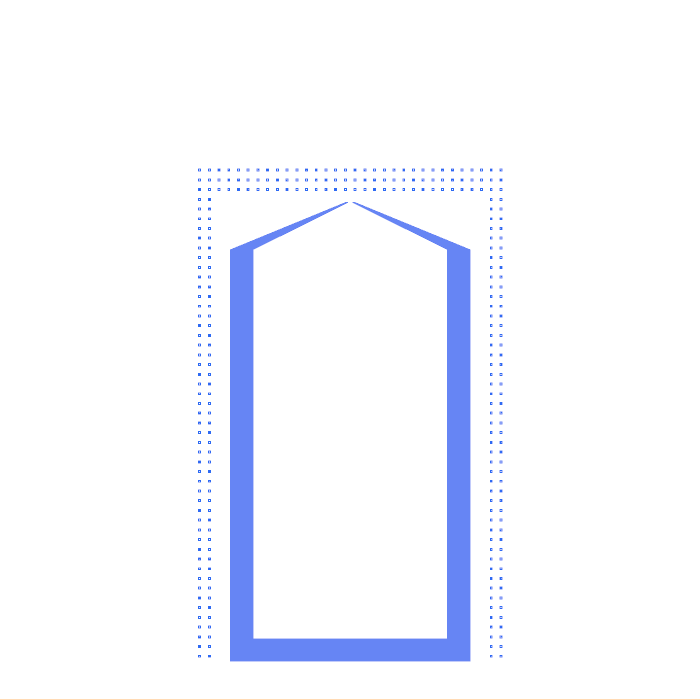

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_pads.png')

In [5]:
with d.batch():
    for n, (x, y), r, e in (("P1_C", (0, -5000), 90, "s"), ("P2_C", (-13000, -5000), 90, "s"),
                            ("P3_C", (15000, 7000), 180, "e")):
        d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e, pad_width="0.5mm", pad_height="1mm",
              lead_length="0um")
rebuild(d)
display(Markdown(pads_md(d)))
TIE = {n: port_xy(d, f"{n}.tie") for n in ("P1_C", "P2_C", "P3_C")}
print("pad ties (µm):", {n: (round(x, 1), round(y, 1)) for n, (x, y) in TIE.items()})
snap(d, OUT / "iswap1_concentric_direct_step_pads.png", box=(TIE["P2_C"][0] - 900, 0, TIE["P2_C"][0] + 900, 1800),
     size=(700, 700), width=300)

## 5 · Components: the concentric qubits, the lumped resonators and their pockets

**The qubits.** `metal:TransmonConcentricType2` (a disk inside a ring with a SQUID between them, three fingers
`pin1`–`pin3`), at −45° and 135°. The source's qubits are SQUIDs, so each gets a **Quantcore SQUID** sized on the PDK
junction rule. The mm-scale islands have C_Σ ≈ 791 fF (this design's LOM before the rebuild): the PDK nominal SQUID
would put them at ≈ 2.1 GHz, so each is sized for 4.0 GHz, the bottom of the PDK band — L_J ≈ 1.85 nH, R_n ≈ 12 kΩ,
**far below the 40–50 kΩ window** (printed): this geometry and the PDK window are incompatible at 4–8 GHz; it is
flagged, not hidden. `junction=` carries L_J / C_J to the LOM.

**The resonators.** `metal:ResonatorLumped` (a 14-turn meander in a 5 × 5 mm metal frame) at ±45°.

**The pockets** (`metal:Rectangle`, `subtract: true`): 10 × 10 mm on each qubit, the frame's inside plus a slot on
each resonator (see the substitutions above). **The drive end:** a `metal:OpenToGround` 500 µm below qubit 1's ring.

{'Lj_nH': 1.8501, 'Cj_fF': 54.6} R_n 12.4 kΩ, fingers 0.91 × 0.6 µm; R_n 12.4 kΩ is outside the process window 40–50 kΩ (f_q 4 GHz with C_Σ 845.8 fF needs E_J/h 88.3 GHz)


qubit1 ports: ['pin1', 'pin2', 'pin3', 'squid_a', 'squid_b'] | resonator1 ports: ['pin_east', 'pin_n', 'pin_ne', 'pin_nw', 'pin_s', 'pin_se', 'pin_sw', 'pin_west']


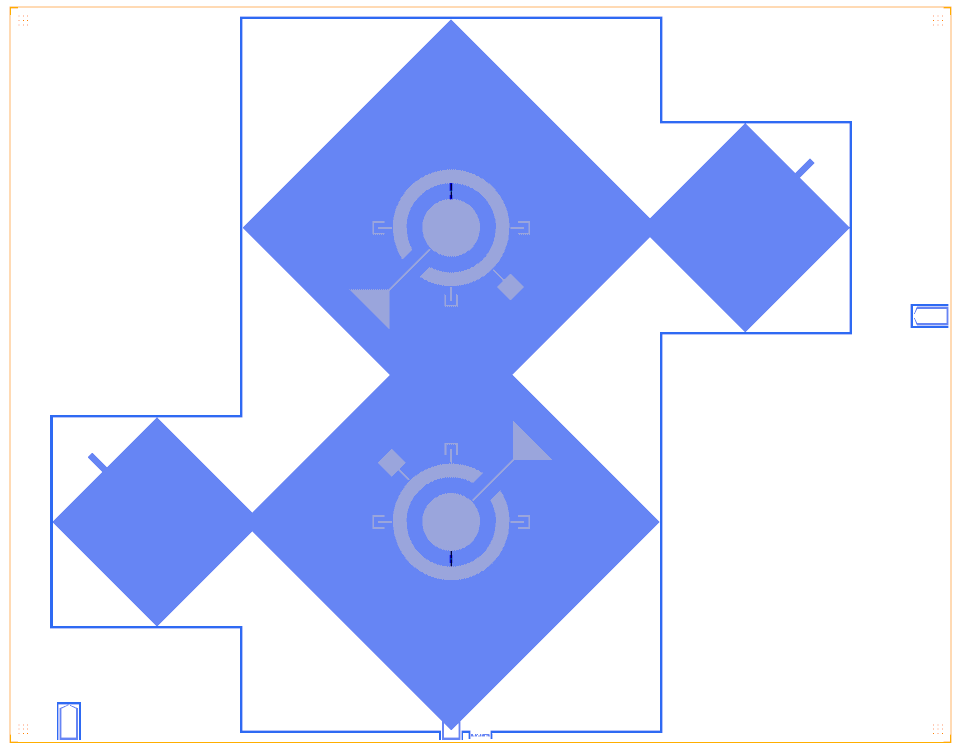

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_parts.png')

In [6]:
# Quantcore SQUIDs (the source's qubits are SQUIDs) on the PDK rule. The mm-scale islands have C_Σ ≈ 791 fF (this
# design's LOM before the rebuild): the PDK nominal SQUID would put them at ≈ 2.1 GHz, so each is sized for 4.0 GHz,
# the bottom of the PDK band — R_n ≈ 12 kΩ, far below the 40–50 kΩ window (printed)
SIZED = size_junction(4.0, 791.2, n=2, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonConcentricType2", lj_nH=SIZED.lj_nH, squid=True)
print(JUNCTION, f"R_n {SIZED.rn_kohm:.1f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)
with d.batch():
    for n, (x, y), r in (("qubit1", (0, 0), -45), ("qubit2", (0, 10000), 135)):
        d.add(n, "metal:TransmonConcentricType2", at=P(x, y), rot=r, junction=JUNCTION, **JJ_PARAMS)
        # the pocket Metal computes (pocket_w × pocket_h, rotated with the qubit) but leaves commented out
        d.add(f"{n}_pocket", "metal:Rectangle", at=P(x, y), rot=r, width=10000, height=10000, subtract=True)
    for n, (x, y), r in (("resonator1", (10000, 10000), -45), ("resonator2", (-10000, 0), 45)):
        d.add(n, "metal:ResonatorLumped", at=P(x, y), rot=r)
        # pocket: inside the 10 µm frame, plus a slot through the 200 µm top break around `final` (pin_n at +3110)
        d.add(f"{n}_pocket", "metal:Rectangle", at=P(x, y), rot=r, width=4980, height=4980, subtract=True)
        dx, dy = turn(0, 2850, r)
        d.add(f"{n}_slot", "metal:Rectangle", at=P(x + dx, y + dy), rot=r, width=200, height=720, subtract=True)
    d.add("open1i", "metal:OpenToGround", at=P(0, -2500), rot=90)
print("qubit1 ports:", sorted(d["qubit1"].ports), "| resonator1 ports:", sorted(d["resonator1"].ports))
snap(d, OUT / "iswap1_concentric_direct_step_parts.png", size=(960, 750), width=400)

## 6 · Lines, wires and the drive coupling

There are no qcc routes in this design: every line of the source is drawn as Metal geometry.
- **Inside a qubit pocket** (route1 between the two `pin2` fingers, route2 / route3 from the `pin3` fingers to the
  resonator frames, route6 from the drive end to `P1_C`): the 100 µm trace as a metal `metal:Rectangle` (Metal draws
  it over the pocket; the gap is inside the pocket anyway), joined to the pins by **wires** (`d.couple(...,
  wire=True)`: a galvanic connection the LOM counts, no drawn route). `P1_C`'s pad now lies at the south tip of qubit
  1's pocket, which would etch the part inside it, so that part is drawn as a 500 µm-wide metal patch (from 100 µm
  below the pocket's tip, clear of the frame's 100 µm die margin, up to the taper).
- **Outside the pockets** (route4 / route5 from the resonators' side pins to `P3_C` / `P2_C`): `metal:PolylineCPW`
  (100 / 6 µm) on Metal's own corner points, wired to the pins at both ends.
- **Pad rule follow-up:** route6, the patch and the last point of each polyline are placed **from the pad ties of
  step 4** (`TIE`), so the 100 µm rule only lengthens their final straight lead.
- **Drive coupling:** the drive line's 100 µm open end faces qubit 1's 500 µm ring across 500 µm with no ground near
  (inside the pocket): a coplanar-strip estimate, declared as `Cd_qubit1` (rough).
- **Sim group** `qubits`: both qubits with their pockets and route1 (Q3D C-matrix).

C_d(drive end ↔ qubit1 ring): 6.0 fF (estimate)


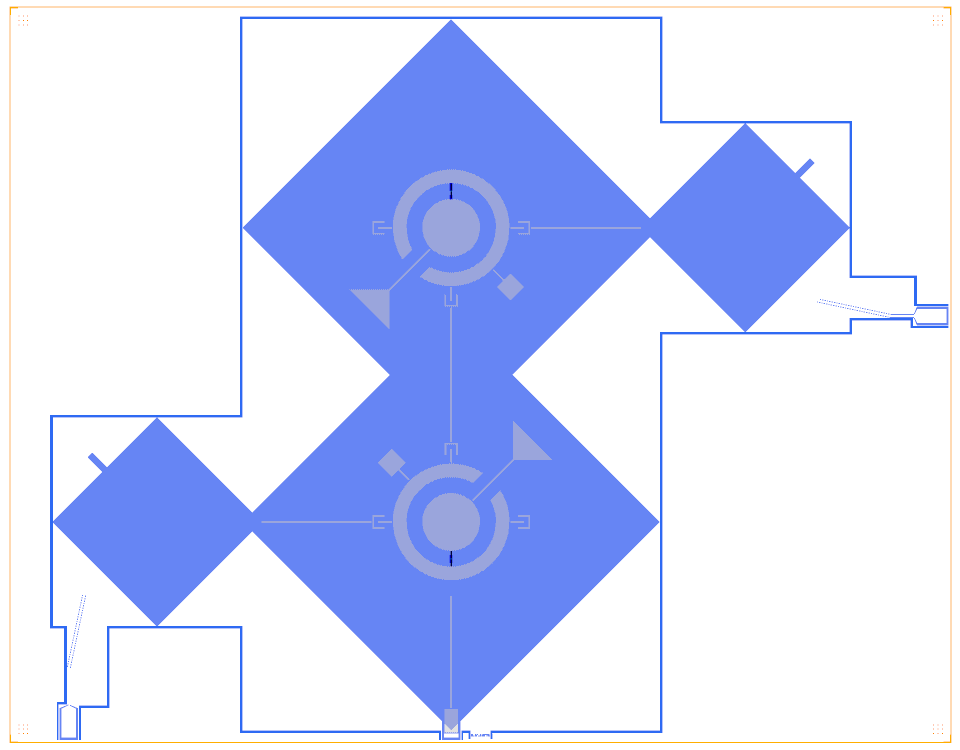

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_routes.png')

In [7]:
EPS = est.substrate_eps(get_pdk())
C_D = round(est.coplanar_coupling(100, 100, 500, 500, EPS), 2)
print("C_d(drive end ↔ qubit1 ring):", C_D, "fF (estimate)")
mm = lambda xy: [round((xy[0] - X0) / 1000, 5), round((xy[1] - Y0) / 1000, 5)]   # Designer µm → Metal mm
t1x, t1y = TIE["P1_C"]                           # P1_C's tie: its pad hangs 122 µm (taper) + 1000 µm below it
with d.batch():
    # lines inside a qubit pocket: their 100 µm trace, joined to the pins by wires
    for n, a, b, (x0, y0), (x1, y1) in (("route1", "qubit1.pin2", "qubit2.pin2", P(0, 2700), P(0, 7300)),
                                       ("route2", "resonator1.pin_sw", "qubit2.pin3", P(6464.47, 10000), P(2700, 10000)),
                                       ("route3", "resonator2.pin_se", "qubit1.pin3", P(-6464.47, 0), P(-2700, 0)),
                                       ("route6", "open1i.open", "P1_C.tie", P(0, -2500), (t1x, t1y - 122))):
        d.add(n, "metal:Rectangle", at=((x0 + x1) / 2, (y0 + y1) / 2),
              rot=math.degrees(math.atan2(y1 - y0, x1 - x0)), width=math.hypot(x1 - x0, y1 - y0), height=100)
        d.couple(f"w_{n}", a, b, wire=True)
    # P1_C's pad lies at the tip of qubit1's pocket, which would etch it: the part inside the pocket is drawn as
    # metal (route6 covers its taper); it starts 100 µm below the pocket's tip, clear of the 100 µm die margin
    tip = P(0, 0)[1] - 5000 * math.sqrt(2)       # the 10 mm pocket, rotated 45°: its south corner
    bottom = max(t1y - 1122, tip - 100)
    d.add("P1_C_pad", "metal:Rectangle", at=(t1x, (bottom + t1y - 122) / 2), width=500, height=t1y - 122 - bottom)
    # lines outside the pockets: Metal's CPW on Metal's own route points (mm, Metal frame), ending at the pad ties
    for n, a, b, pts in (
        ("route4", "resonator1.pin_east", "P3_C.tie", [[11.76777, 8.23223], [12.47487, 7.52513], [14.95, 7.0],
                                                       mm(TIE["P3_C"])]),
        ("route5", "resonator2.pin_west", "P2_C.tie", [[-11.76777, -1.76777], [-12.47487, -2.47487], [-13.0, -4.95],
                                                       mm(TIE["P2_C"])])):
        d.add(n, "metal:PolylineCPW", at=P(0, 0), points=pts, **LINE)
        d.couple(f"w_{n}_start", a, f"{n}.start", wire=True)
        d.couple(f"w_{n}_end", b, f"{n}.end", wire=True)
    d.couple("Cd_qubit1", "qubit1.island1", "open1i.open", C_fF=C_D, note="drive end 500 µm below the ring (CPS, rough)")
# FEM box: both qubits with their pockets and the line between them
d.sim_group("qubits", ["qubit1", "qubit2", "route1", "qubit1_pocket", "qubit2_pocket"], margin_um=200,
            analyses=["q3d_cmatrix"])
rebuild(d)
snap(d, OUT / "iswap1_concentric_direct_step_routes.png", size=(960, 750), width=400)

## 7 · Centring and save

The PDK wants the chip content centred in the die. This source is off-centre **on purpose**: Metal centres its
32 × 20 mm chip at x = 1 mm so that the east launchpad fits, while the qubits, their 10 mm pockets and the two
resonators are centred on x = 0; the rebuild's box keeps that (Designer = Metal + (15, 7.5) mm). The pad rule then
moved P1_C / P2_C to the south edge and P3_C to the east edge. The cell measures the offsets of everything placed, of
the content without the pads and of the circuit core (qubits, resonators and their pockets), and tries
`center_in_die` on a copy: it counts the pads, which slide back to their edges after a shift, so it would move the
core further west (and break the pad-linked geometry of step 6). The design keeps the source's placement. Then it is
saved: the JSON is the deliverable.

In [8]:
from collections import Counter
from kqcircuits.pya_resolver import pya
from quantcore_circuits.assembly.sidecar import sidecar_dict
from _common import _pad_instances


def centre_offsets(d, core=()):
    """Content centre − die centre (µm): of everything placed, without the bond pads, and of the ``core`` instances."""
    side, pads = sidecar_dict(rebuild(d), overlays=False), set(_pad_instances(d))
    x0, y0, x1, y1 = d.design.chip.box
    out = {}
    for label, keep in (("everything", lambda n: True), ("without the pads", lambda n: n not in pads),
                        ("circuit core", lambda n: n in core)):
        box = pya.DBox()
        for n, inst in side["instances"].items():
            if inst.get("bbox") and keep(n):
                box += pya.DBox(*inst["bbox"])
        if label != "circuit core":
            for route in side["routes"].values():
                for x, y in route.get("polyline") or []:
                    box += pya.DPoint(x, y)
        out[label] = (round(box.center().x - (x0 + x1) / 2), round(box.center().y - (y0 + y1) / 2))
    return out


CORE = ["qubit1", "qubit2", "qubit1_pocket", "qubit2_pocket", "resonator1", "resonator2", "resonator1_pocket",
        "resonator2_pocket"]
print("content centre − die centre (µm):", centre_offsets(d, CORE))
DESIGN = d.save(OUT / "iswap1_concentric_direct.json")
trial = design_copy(DESIGN, "_centred")          # what center_in_die would do, on a copy
print("center_in_die on a copy: shift", center_in_die(trial), "µm → circuit core then at",
      centre_offsets(trial, CORE)["circuit core"], "µm from the die centre")
print(d, "→", DESIGN)

content centre − die centre (µm): {'everything': (396, -164), 'without the pads': (-194, -52), 'circuit core': (-1000, 0)}


center_in_die on a copy: shift (-395.9, 164.5) µm → circuit core then at (-1396, 164) µm from the die centre
<Designer iswap1_concentric_direct: 21 instances, 0 routes, live=False> → examples\designs\metal\iswap1_concentric_direct.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**. `dangling_port`: the unused pins (each qubit's `pin1`, six of each resonator's
frame pins and its open `pin_n`), the junction attachment points `squid_a` / `squid_b` (drawn by the cell), and the
ends joined by wires (the DRC does not count wire couplings yet, see lom's request). Every `overlap` is a pocket by
design: the two 10 mm qubit pockets overlap each other, the resonators' corners and the lines and patch inside them;
each resonator overlaps its own pocket, slot and lines; P1_C sits at the tip of qubit 1's pocket. **PDK design
warnings:** `pdk_rn` on both qubits: the SQUID is 12.4 kΩ (two ≈ 24.7 kΩ junctions in parallel), far below the
40–50 kΩ window, because mm-scale islands need L_J ≈ 1.85 nH to reach 4 GHz; flagged, not retuned. No `pad_edge`: the three
pads are at 100 µm.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 62 warnings · 2 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 18 | qubit1.pin1 is not connected (no route or snap) |
| warning | `overlap` | 44 | P1_C and P1_C_pad overlap |
| PDK design warning | `pdk_rn` | 2 | qubit1: junction R_n 12.4 kΩ is outside the PDK window 40–50 kΩ (L_J 1.8501 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+396, -164) µm |
| junction types | Quantcore Squid × 2 |
| PDK design warnings | 2 (pdk_rn × 2) |
| pdk_rn | qubit1: junction R_n 12.4 kΩ is outside the PDK window 40–50 kΩ (L_J 1.8501 nH) |
| pdk_rn | qubit2: junction R_n 12.4 kΩ is outside the PDK window 40–50 kΩ (L_J 1.8501 nH) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: `TransmonConcentricType2` on its pocket → two floating islands
(`island1` ring, `island2` disk) with the SQUID between, and a coupler node per finger (`pin1`–`pin3`);
`ResonatorLumped` on its pocket → a λ/4 line of its trace length (69.8 mm, shorted to the frame = ground, open at
`pin_n`; rough: no inter-turn coupling). route1 joins the two `pin2` fingers into one node (a wire: its own
capacitance is not in the LOM). The `pin3` fingers are wired to the grounded frames, so their coupling capacitances
go to ground. The drive line is the `P1_C` 50 Ω port node with the assumed `Cd_qubit1` to the ring. P2_C / P3_C are
shorted by the frames (their ports are dropped).

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("qubit1.", "P1_C."))})

**11 nodes · 22 branches · 0 controls · 14 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `open1i.end` | `P1_C.pad`, `open1i.end` |
| `qubit1.island1` | `qubit1.island1` |
| `qubit1.island2` | `qubit1.island2` |
| `qubit1.pin1` | `qubit1.pin1` |
| `qubit1.pin2` | `qubit1.pin2`, `qubit2.pin2` |
| `qubit2.island1` | `qubit2.island1` |
| `qubit2.island2` | `qubit2.island2` |
| `qubit2.pin1` | `qubit2.pin1` |
| `resonator1.res` | `resonator1.res` |
| `resonator2.res` | `resonator2.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P1_C` | R | `open1i.end` – `gnd` | 50 Ω |
| `C_qubit1_1` | C | `qubit1.island1` – `gnd` | 590 fF |
| `C_qubit1_2` | C | `qubit1.island2` – `gnd` | 82 fF |
| `C_qubit1_12` | C | `qubit1.island1` – `qubit1.island2` | 740 fF |
| `J_qubit1` | SQUID | `qubit1.island1` – `qubit1.island2` | Lj 1.85 nH, Cj 54.6 fF |
| `Cg_qubit1_pin1` | C | `qubit1.island1` – `qubit1.pin1` | 46 fF |
| `Cc_qubit1_pin1` | C | `qubit1.pin1` – `gnd` | 64 fF |
| `Cg_qubit1_pin2` | C | `qubit1.island1` – `qubit1.pin2` | 46 fF |
| `Cc_qubit1_pin2` | C | `qubit1.pin2` – `gnd` | 64 fF |
| `Cg_qubit1_pin3` | C | `qubit1.island1` – `gnd` | 46 fF |
| `C_qubit2_1` | C | `qubit2.island1` – `gnd` | 590 fF |
| `C_qubit2_2` | C | `qubit2.island2` – `gnd` | 82 fF |
| `C_qubit2_12` | C | `qubit2.island1` – `qubit2.island2` | 740 fF |
| `J_qubit2` | SQUID | `qubit2.island1` – `qubit2.island2` | Lj 1.85 nH, Cj 54.6 fF |
| `Cg_qubit2_pin1` | C | `qubit2.island1` – `qubit2.pin1` | 46 fF |
| `Cc_qubit2_pin1` | C | `qubit2.pin1` – `gnd` | 64 fF |
| `Cg_qubit2_pin2` | C | `qubit2.island1` – `qubit1.pin2` | 46 fF |
| `Cc_qubit2_pin2` | C | `qubit1.pin2` – `gnd` | 64 fF |
| `Cg_qubit2_pin3` | C | `qubit2.island1` – `gnd` | 46 fF |
| `C_Cd_qubit1` | C | `qubit1.island1` – `open1i.end` | 6 fF |
| `resonator1` | TLres | `resonator1.res` – `gnd` | lambda/4, 69800 µm, 0.451 GHz |
| `resonator2` | TLres | `resonator2.res` – `gnd` | lambda/4, 69800 µm, 0.451 GHz |

**Unconnected ports:** `qubit1.pin1`, `qubit2.pin1`, `resonator1.pin_n`, `resonator1.pin_ne`, `resonator1.pin_nw`, `resonator1.pin_s`, `resonator1.pin_se`, `resonator1.pin_west`, `resonator2.pin_east`, `resonator2.pin_n`, `resonator2.pin_ne`, `resonator2.pin_nw`, `resonator2.pin_s`, `resonator2.pin_sw`

**Builder notes:**

- resonator1: lumped resonator estimated as a λ/4 line of its trace length (rough)
- resonator2: lumped resonator estimated as a λ/4 line of its trace length (rough)
- Port_P2_C: both ends on gnd after merging conductors (dropped)
- Port_P3_C: both ends on gnd after merging conductors (dropped)
- Cc_qubit1_pin3: both ends on gnd after merging conductors (dropped)
- Cc_qubit2_pin3: both ends on gnd after merging conductors (dropped)

{'P1_C.tie': 'open1i.end', 'qubit1.squid_a': 'qubit1.island1', 'qubit1.squid_b': 'qubit1.island2', 'qubit1.pin1': 'qubit1.pin1', 'qubit1.pin2': 'qubit1.pin2', 'qubit1.pin3': 'gnd'}


## 10 · LOM simulation

Both qubits with the line between them and the drive port, then each resonator alone.

- qubit1 / qubit2 at the 4.0 GHz the SQUIDs were sized for (mm-scale islands: C_Σ ≈ 0.8 pF, E_C ≈ 24 MHz). The two
  qubits are identical, so their modes hybridise through route1 (participations ≈ 0.5 each, each mode's
  anharmonicity about half of E_C): ZZ is not defined for degenerate qubits. κ through the drive line is tiny (the
  assumed 6 fF).
- resonator1 / resonator2: λ/4 of the 69.8 mm meander, ≈ 0.45 GHz (rough: no inter-turn coupling, which would lower
  it), κ 0 (nothing couples to it, see the substitutions).

In [11]:
pair = simulate_groups(d, {"qubit1+route1+qubit2": ["qubit1", "qubit2", "route1", "open1i", "route6", "P1_C"]},
                       max_modes=2)
display(Markdown("**qubit1–route1–qubit2, QuCat normal modes:**\n\n" + modes_md(pair["qubit1+route1+qubit2"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pair)))
res = simulate_groups(d, {"resonator1": ["resonator1"], "resonator2": ["resonator2"]}, max_modes=1)
for g, r in res.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))

**qubit1–route1–qubit2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| qubit1 | qubit | 3.9717 | 0.00149 | 12.1 | J_qubit1 0.65, J_qubit2 0.35 |
| qubit2 | qubit | 3.9723 | 0.000852 | 12.2 | J_qubit2 0.65, J_qubit1 0.35 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| qubit1+route1+qubit2 | qubit1-qubit2 | – | yes | yes |

**resonator1:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| resonator1 | resonator | 0.4509 | 0 | 0.0 | resonator1 1.00 |

**resonator2:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| resonator2 | resonator | 0.4509 | 0 | 0.0 | resonator2 1.00 |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One job: a **Q3D C-matrix** for the two qubits, their pockets and route1; it replaces the LOM's rough disk /
ring / finger estimates by net name.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["qubits"])
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| qubits | `build/jobs/iswap1_concentric_direct_qubits_q3d_cmatrix` | 1 · junction · `qubit1.junction`<br>2 · junction · `qubit2.junction` | `qubit1.island1`, `qubit2.island1`, `qubit1.pin1`, `qubit1.island2`, `qubit1.pin2`, `qubit2.pin1`, `qubit2.island2` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['qubits'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for qubits · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here the SQUIDs' L_J, re-sized for 4.5 GHz instead of 4.0 GHz (smaller L_J, larger fingers, R_n even further below the
window) — and re-run the qubit pair. The pair moves up by ≈ 0.5 GHz; the anharmonicity (set by E_C) barely moves.

In [15]:
S45 = size_junction(4.5, 791.2, n=2, c_includes_junction=False)
P45, J45 = trilayer_junction("metal:TransmonConcentricType2", lj_nH=S45.lj_nH, squid=True)
print(f"4.5 GHz: L_J {S45.lj_nH:.3f} nH, R_n {S45.rn_kohm:.1f} kΩ")
d2 = design_copy(DESIGN)
for n in ("qubit1", "qubit2"):
    d2[n].set(junction=J45, **P45)               # L_J 1.85 → ≈ 1.46 nH
pair2 = simulate_groups(d2, {"qubit1+route1+qubit2": ["qubit1", "qubit2", "route1", "open1i", "route6", "P1_C"]},
                        max_modes=2)
display(Markdown(params_delta_md(pair, pair2)))

4.5 GHz: L_J 1.438 nH, R_n 9.6 kΩ


| parameter | before | after | Δ |
|---|---|---|---|
| `qubit1+route1+qubit2: qubit1.f_q_GHz` | 3.9493 | 4.4415 | +0.4922 |
| `qubit1+route1+qubit2: qubit1.alpha_MHz` | -22.236 | -21.762 | +0.474 |
| `qubit1+route1+qubit2: qubit2.f_q_GHz` | 3.9498 | 4.4421 | +0.4923 |
| `qubit1+route1+qubit2: qubit2.alpha_MHz` | -0.5234 | -0.57659 | -0.05318 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). On this 32 × 25 mm board the fab
export (cheese + corner rounding) is the slowest cell.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\iswap1_concentric_direct.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 13735 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 13719 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 13715 holes on the mask.

→ `build/iswap1_concentric_direct_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot of Example 1); qubit 1 with its fingers, the drive line and route1;
its SQUID between disk and ring; resonator 1's top corner with the slot around `final`; P1_C on the south edge at the
tip of qubit 1's pocket (its metal patch and route6); the **fab mask** at the tip of qubit 1's pocket (1/0 etch with
the PDK cheese band along the pocket edges, the 3/0 keep-out, P1_C); and the die frame's south-west corner.

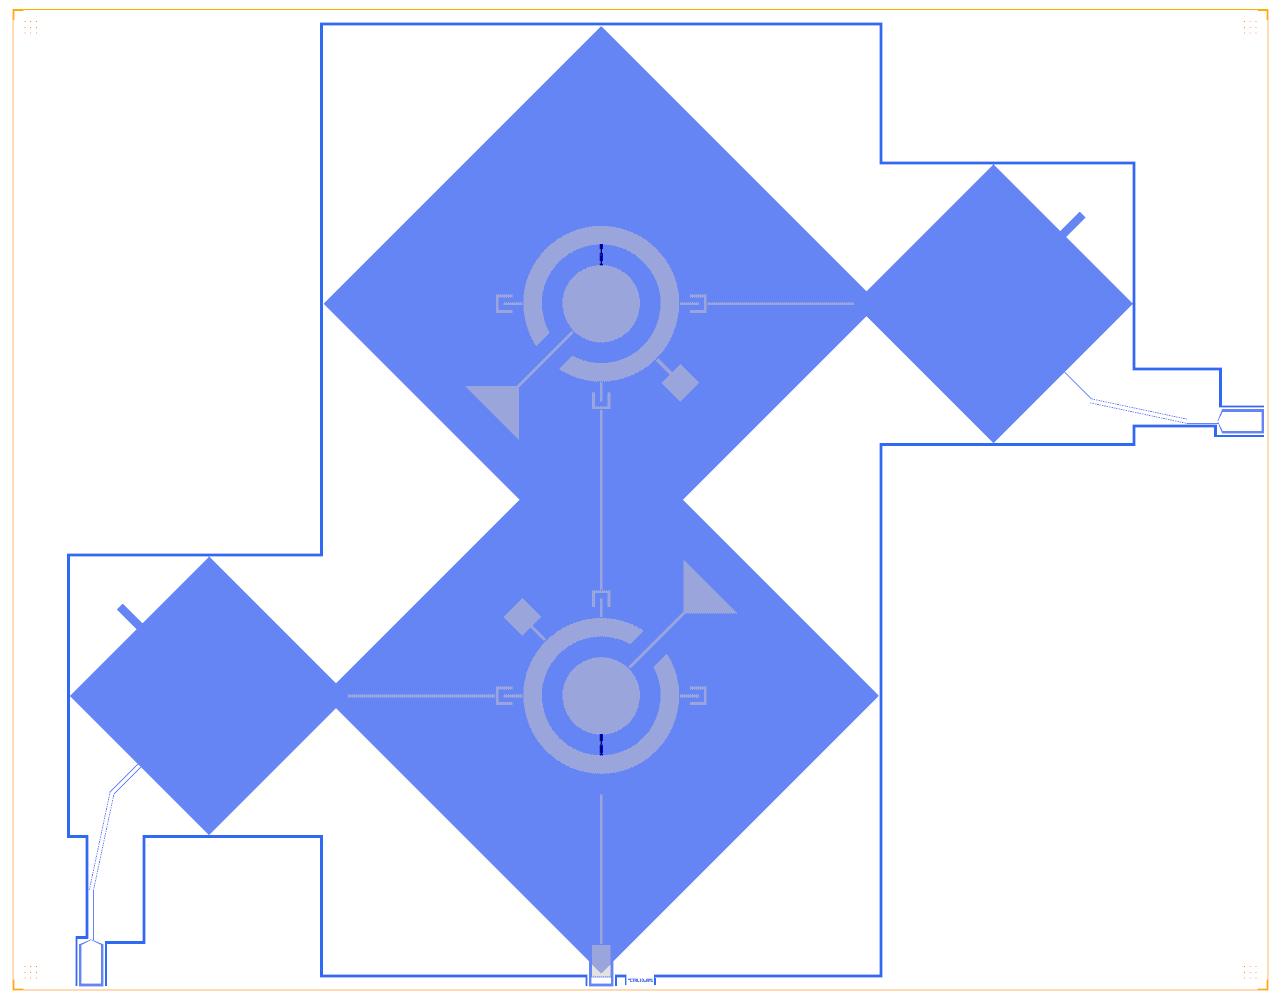

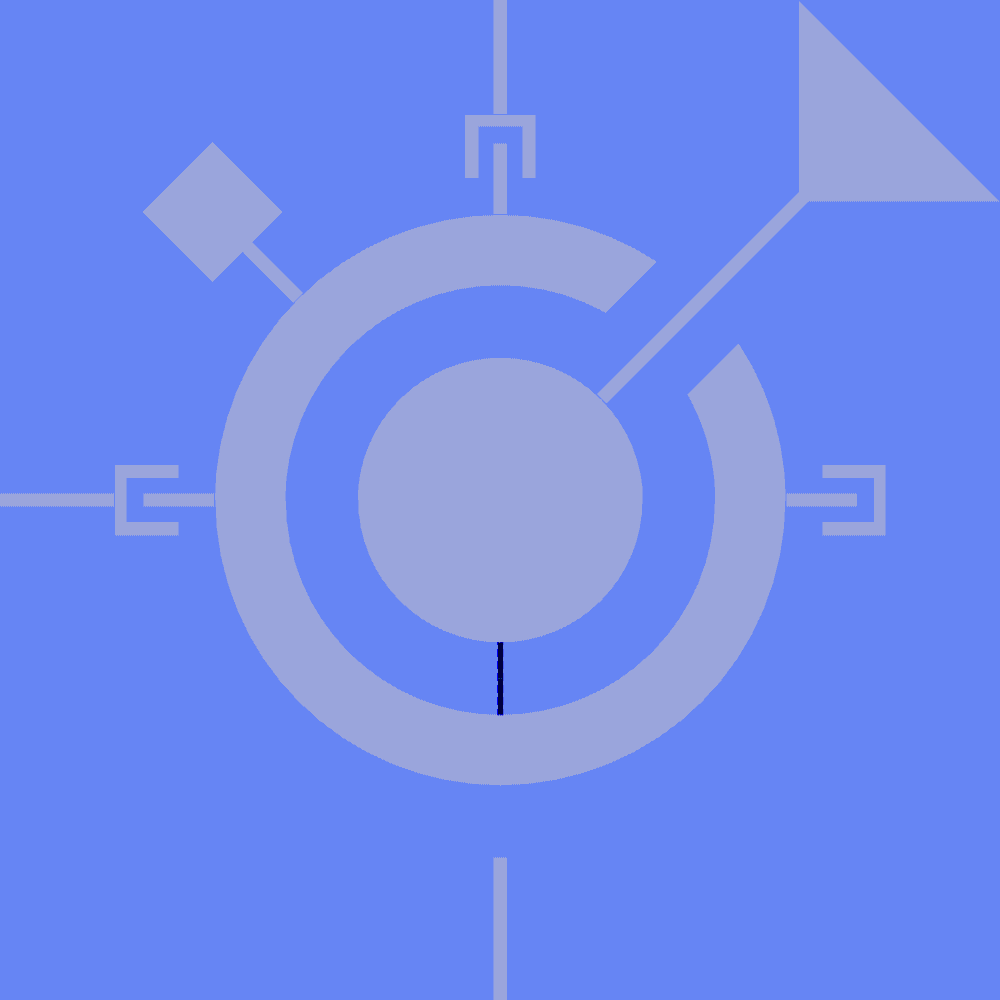

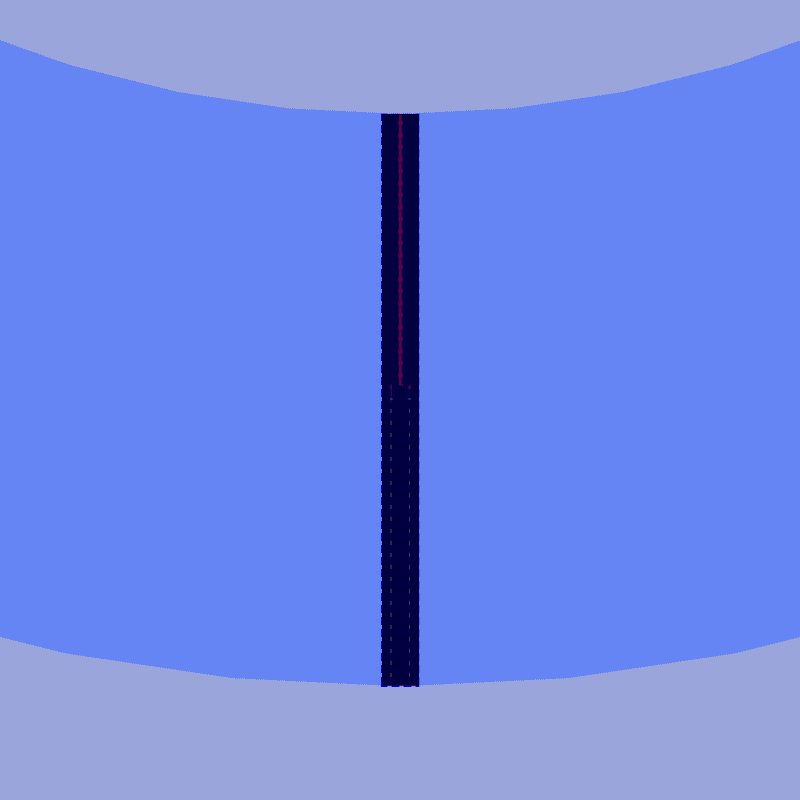

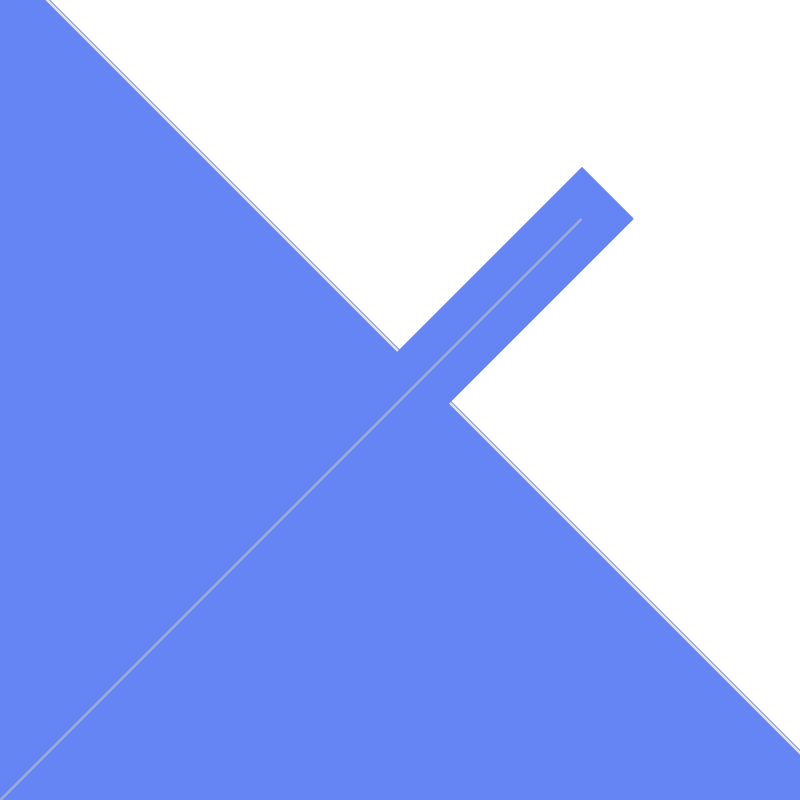

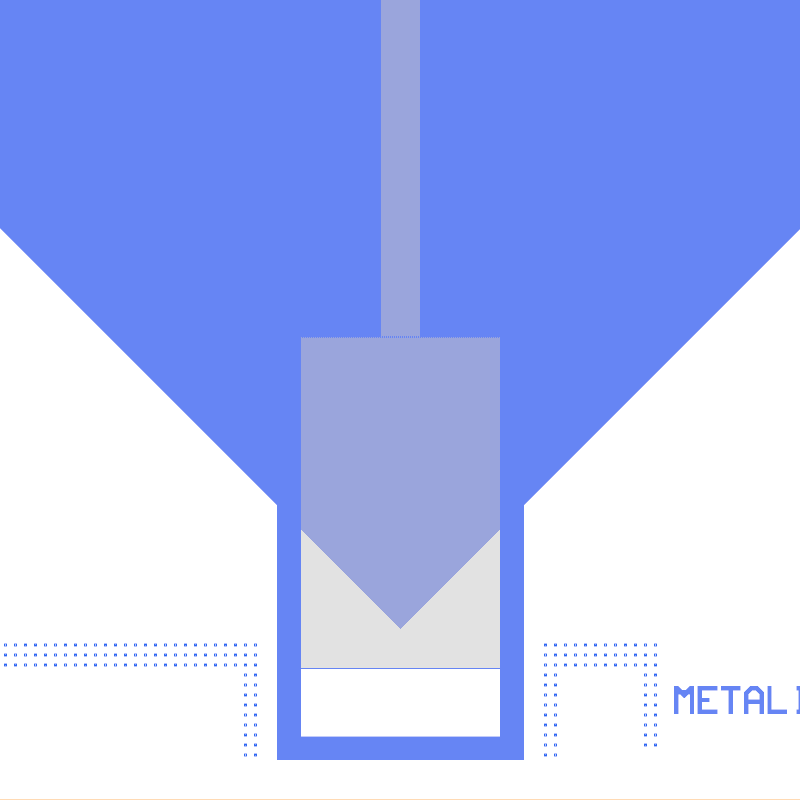

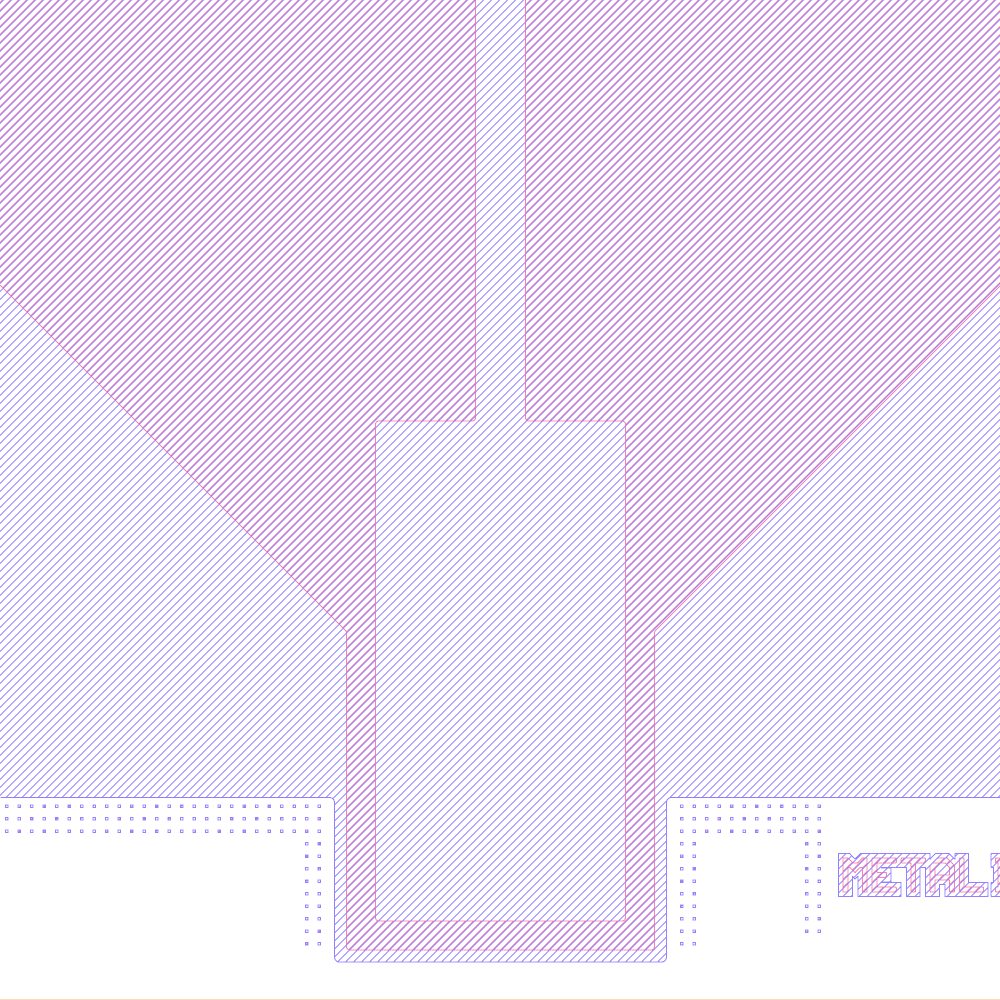

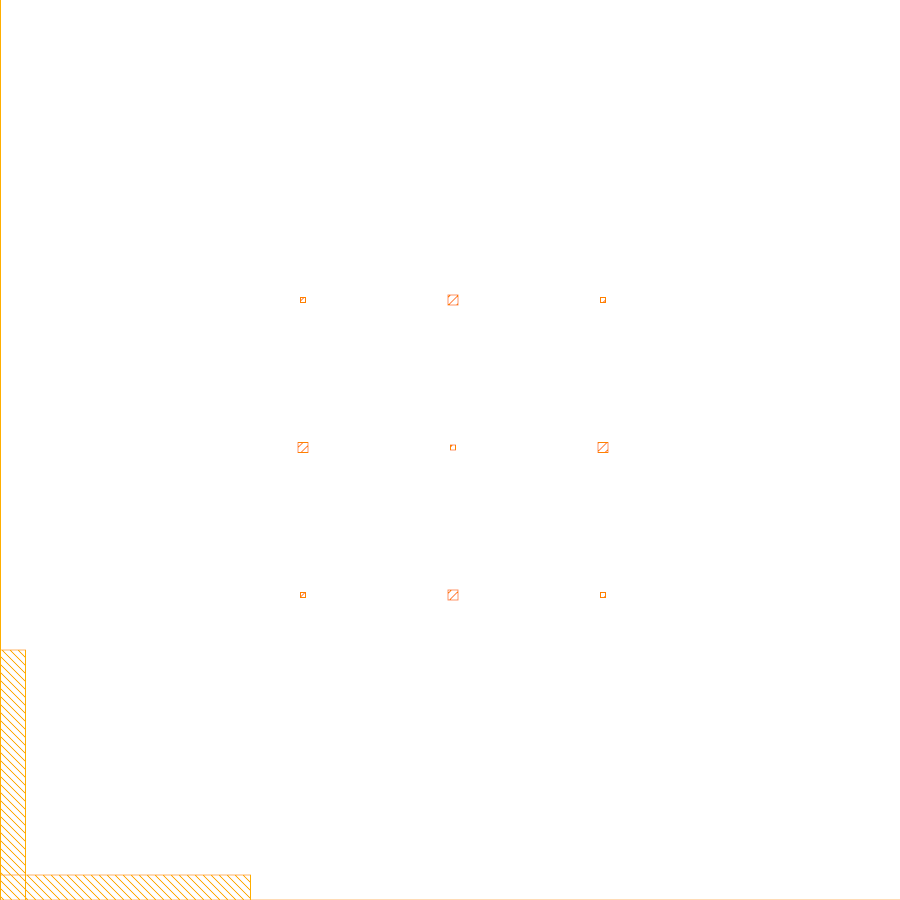

In [17]:
show_snapshot(d, OUT / "iswap1_concentric_direct.png", size=(1280, 1000))
show_snapshot(d, OUT / "iswap1_concentric_direct_q1.png", box=P(-3500, -3500) + P(3500, 3500), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "iswap1_concentric_direct_jj.png", box=P(-350, -1600) + P(350, -900), size=(800, 800), width=320)
show_snapshot(d, OUT / "iswap1_concentric_direct_res.png", box=P(10600, 10600) + P(12800, 12800), size=(800, 800), width=320)
show_snapshot(d, OUT / "iswap1_concentric_direct_pad.png", box=(t1x - 1000, 0, t1x + 1000, 2000), size=(800, 800), width=320)
snap_file(Path("build") / "iswap1_concentric_direct_fab.oas", OUT / "iswap1_concentric_direct_cheese.png",
          box=(t1x - 1000, 0, t1x + 1000, 2000), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "iswap1_concentric_direct_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, positions and orientations, every line on Metal's route points, the sim group |
| PDK changes | QCT frame on a 32 × 25 mm box; sapphire stack; launchpads 100 µm from the south (P1_C, P2_C) and east (P3_C) edges (were 1320 / 1320 / 820 µm in), with their patch, route6 and the polyline ends following the ties; trilayer SQUIDs sized for 4.0 GHz; PDK cheese band |
| differs | the pockets Metal never draws are added; lines inside the pockets are metal strips + wires; the resonators couple to nothing (frame pins are ground once the pockets exist); the source's off-centre placement is kept (step 7) |
| PDK design warnings | `pdk_rn` × 2 (SQUIDs at 12.4 kΩ: mm-scale islands need L_J ≈ 1.85 nH at 4 GHz) |
| open | the coupling estimates (wire, drive) until the Q3D job is solved (`RUN_FEM = False`); wires are not counted by the DRC's `dangling_port` |